In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")
import numpy as np
import matplotlib.pyplot as plt
from src.logreg import sigmoid, loss, gradients, train, predict_proba

In [2]:
print(sigmoid(np.array([-2, 0, 2])))            # expect [0.119 0.5 0.881]
print(loss(np.array([0.5]), np.array([1])))     # expect 0.693
X = np.array([[1, 0], [1, 1], [0, 1]])
y = np.array([0, 1, 0])
p = np.array([0.2, 0.5, 0.1])
print(gradients(X, y, p))                       # expect ([-0.1, -0.133], -0.067)

[0.11920292 0.5        0.88079708]
0.6931471805599453
(array([-0.1       , -0.13333333]), np.float64(-0.06666666666666667))


In [3]:
data = np.load("../data/features.npz", allow_pickle=True)
X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]
columns = data["columns"]
print(X_train.shape, y_train.mean())

(77181, 261) 0.04652699498581257


In [4]:
   keep = X_train.std(axis=0) > 0
   X_train, X_val = X_train[:, keep], X_val[:, keep]
   columns = columns[keep]
   print(X_train.shape, "removed:", (~keep).sum())

(77181, 260) removed: 1


In [5]:
rate = y_train.mean()
print("baseline val loss:", loss(np.full(len(y_val), rate), y_val))

baseline val loss: 0.15707470837550863


In [6]:
w, b, hist = train(X_train, y_train, lr=0.5, epochs=1000, X_val=X_val, y_val=y_val)
print("final train:", hist["train"][-1], " final val:", hist["val"][-1])

epoch 0: train loss 0.6931
epoch 100: train loss 0.1781
epoch 200: train loss 0.1745
epoch 300: train loss 0.1730
epoch 400: train loss 0.1720
epoch 500: train loss 0.1713
epoch 600: train loss 0.1707
epoch 700: train loss 0.1702
epoch 800: train loss 0.1698
epoch 900: train loss 0.1695
final train: 0.169205474374049  final val: 0.14156051765997982


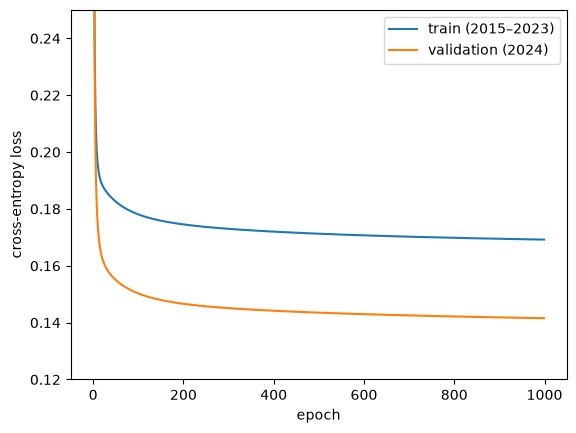

In [7]:
plt.plot(hist["train"], label="train (2015–2023)")
plt.plot(hist["val"], label="validation (2024)")
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.legend()
plt.ylim(0.12, 0.25)
plt.savefig("../plots/loss_logreg.png", dpi=150)
plt.show()

In [8]:
from sklearn.metrics import roc_auc_score
p_val = predict_proba(X_val, w, b)
print("val ROC-AUC:", roc_auc_score(y_val, p_val))

val ROC-AUC: 0.7389157798487831


In [9]:
order = np.argsort(-p_val)
top = order[: len(p_val) // 10]
print("fatal rate in top 10%:", y_val[top].mean())
print("share of all deaths in top 10%:", y_val[top].sum() / y_val.sum())

fatal rate in top 10%: 0.12655367231638417
share of all deaths in top 10%: 0.34890965732087226


In [10]:
idx = np.argsort(w)
print("RAISE risk:")
for i in idx[-10:][::-1]:
    print(f"  {columns[i]:70s} odds x{np.exp(w[i]):.2f}")
print("LOWER risk:")
for i in idx[:10]:
    print(f"  {columns[i]:70s} odds x{np.exp(w[i]):.2f}")

RAISE risk:
  participant_categories_Пешеходы                                        odds x1.80
  participant_categories_Мотоциклисты                                    odds x1.72
  category_Наезд на препятствие                                          odds x1.48
  light_В темное время суток, освещение отсутствует                      odds x1.35
  hour_0                                                                 odds x1.30
  participants_count                                                     odds x1.27
  hour_5                                                                 odds x1.26
  hour_2                                                                 odds x1.24
  hour_6                                                                 odds x1.22
  region_Щаповское поселение                                             odds x1.21
LOWER risk:
  category_Столкновение                                                  odds x0.40
  light_Светлое время суток                         